# Pet Breed Recognition — 37 breeds (Part 2 of the Cats vs Dogs project)

Part 1 told cats from dogs (98.4 % test accuracy). Part 2 asks the harder, fine-grained question:
**which of 37 breeds is it?** Same workflow, shorter text, more models and more visuals.

| Step | Content |
|---|---|
| 1 | Data — Oxford-IIIT Pet (TensorFlow Datasets), 7,349 photos, 25 dog + 12 cat breeds |
| 2 | Quick EDA — breed balance, image sizes, one photo per breed |
| 3 | **Model selection** — 2 baselines, a CNN from scratch, 6 pretrained backbones, 1 ensemble |
| 4 | Tuning — grid search on the best backbone |
| 5 | **Evaluation & visualization** — per-breed scores, confusions, embedding map, Grad-CAM |
| 6 | Summary |

> Colab with a GPU recommended (*Runtime → Change runtime type → T4 GPU*); also runs on a CPU.

In [1]:
import sys, os
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q tensorflow-datasets importlib_resources
try:
    import importlib_resources
except ImportError:
    os.system("pip install -q importlib_resources")

In [2]:
import os, re, gc, json, time, warnings, itertools, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf, tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, top_k_accuracy_score, classification_report
from sklearn.manifold import TSNE

SEED = 42
keras.utils.set_random_seed(SEED)
ON_GPU = len(tf.config.list_physical_devices("GPU")) > 0
SMOKE_TEST = os.environ.get("CVD_SMOKE_TEST") == "1"
IMG = 224                                   # input size of every pretrained backbone
BUDGET = dict(scratch_epochs=40 if ON_GPU else 12, head_epochs=200)
if SMOKE_TEST:
    BUDGET = dict(scratch_epochs=1, head_epochs=3)

RES = "results_breeds"; FIG = os.path.join(RES, "figures"); CACHE = os.path.join(RES, "cache")
for d in (FIG, CACHE):
    os.makedirs(d, exist_ok=True)
REUSE_SAVED = True                          # reuse cached backbone features in results_breeds/cache
RESULTS = {"config": dict(seed=SEED, img=IMG, on_gpu=ON_GPU, tensorflow=tf.__version__, budget=BUDGET)}
warnings.filterwarnings("ignore", category=UserWarning)
tf.get_logger().setLevel("ERROR")                  # hide TensorFlow deprecation notices
sns.set_theme(style="whitegrid")
SPECIES_COLORS = {"Cat": "#E07A5F", "Dog": "#3D5A80"}

def save_fig(name):
    plt.savefig(os.path.join(FIG, f"{name}.png"), dpi=110, bbox_inches="tight")

print("TensorFlow", tf.__version__, "| GPU:", ON_GPU, "| smoke test:", SMOKE_TEST)

TensorFlow 2.21.0 | GPU: False | smoke test: False


## 1. Data
Oxford-IIIT Pet: 37 breeds, ~200 photos each, official train (3,680) / test (3,669) split. We carve a
stratified 15 % validation set out of *train*; the test set is used once, at the end.

In [3]:
(train_raw, test_raw), info = tfds.load("oxford_iiit_pet", split=["train", "test"], with_info=True)
BREEDS = [n.replace("_", " ").title() for n in info.features["label"].names]
SPECIES = info.features["species"].names                     # ['Cat', 'Dog']

def meta(ds):
    rows = []
    for ex in ds.map(lambda e: {"f": e["file_name"], "y": e["label"], "s": e["species"], "shape": tf.shape(e["image"])}).as_numpy_iterator():
        rows.append(dict(file=ex["f"].decode(), label=int(ex["y"]), species=SPECIES[int(ex["s"])],
                         height=int(ex["shape"][0]), width=int(ex["shape"][1])))
    return pd.DataFrame(rows)

meta_train, meta_test = meta(train_raw), meta(test_raw)
if SMOKE_TEST:
    meta_train = meta_train.groupby("label").head(12).reset_index(drop=True)
    meta_test = meta_test.groupby("label").head(6).reset_index(drop=True)
tr_idx, va_idx = train_test_split(np.arange(len(meta_train)), test_size=0.15, stratify=meta_train["label"], random_state=SEED)
meta_train["split"] = "train"; meta_train.loc[va_idx, "split"] = "val"; meta_test["split"] = "test"
meta_all = pd.concat([meta_train, meta_test], ignore_index=True)
meta_all["breed"] = meta_all["label"].map(lambda i: BREEDS[i])
BREED_SPECIES = meta_all.groupby("label")["species"].first().reindex(range(len(BREEDS))).tolist()
print(meta_all["split"].value_counts().to_dict(), "|", len(BREEDS), "breeds:",
      sum(s == "Cat" for s in BREED_SPECIES), "cat,", sum(s == "Dog" for s in BREED_SPECIES), "dog")
RESULTS["data"] = {"counts": meta_all["split"].value_counts().to_dict(), "breeds": BREEDS, "breed_species": BREED_SPECIES}

{'test': 3669, 'train': 3128, 'val': 552} | 37 breeds: 12 cat, 25 dog


## 2. Quick EDA

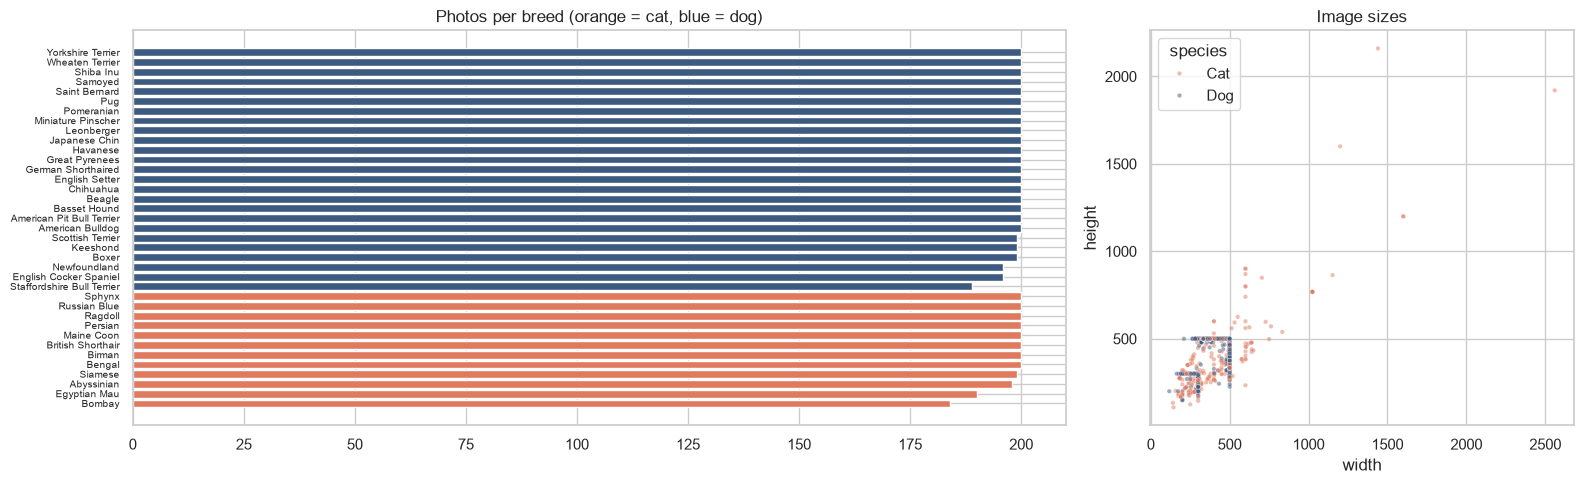

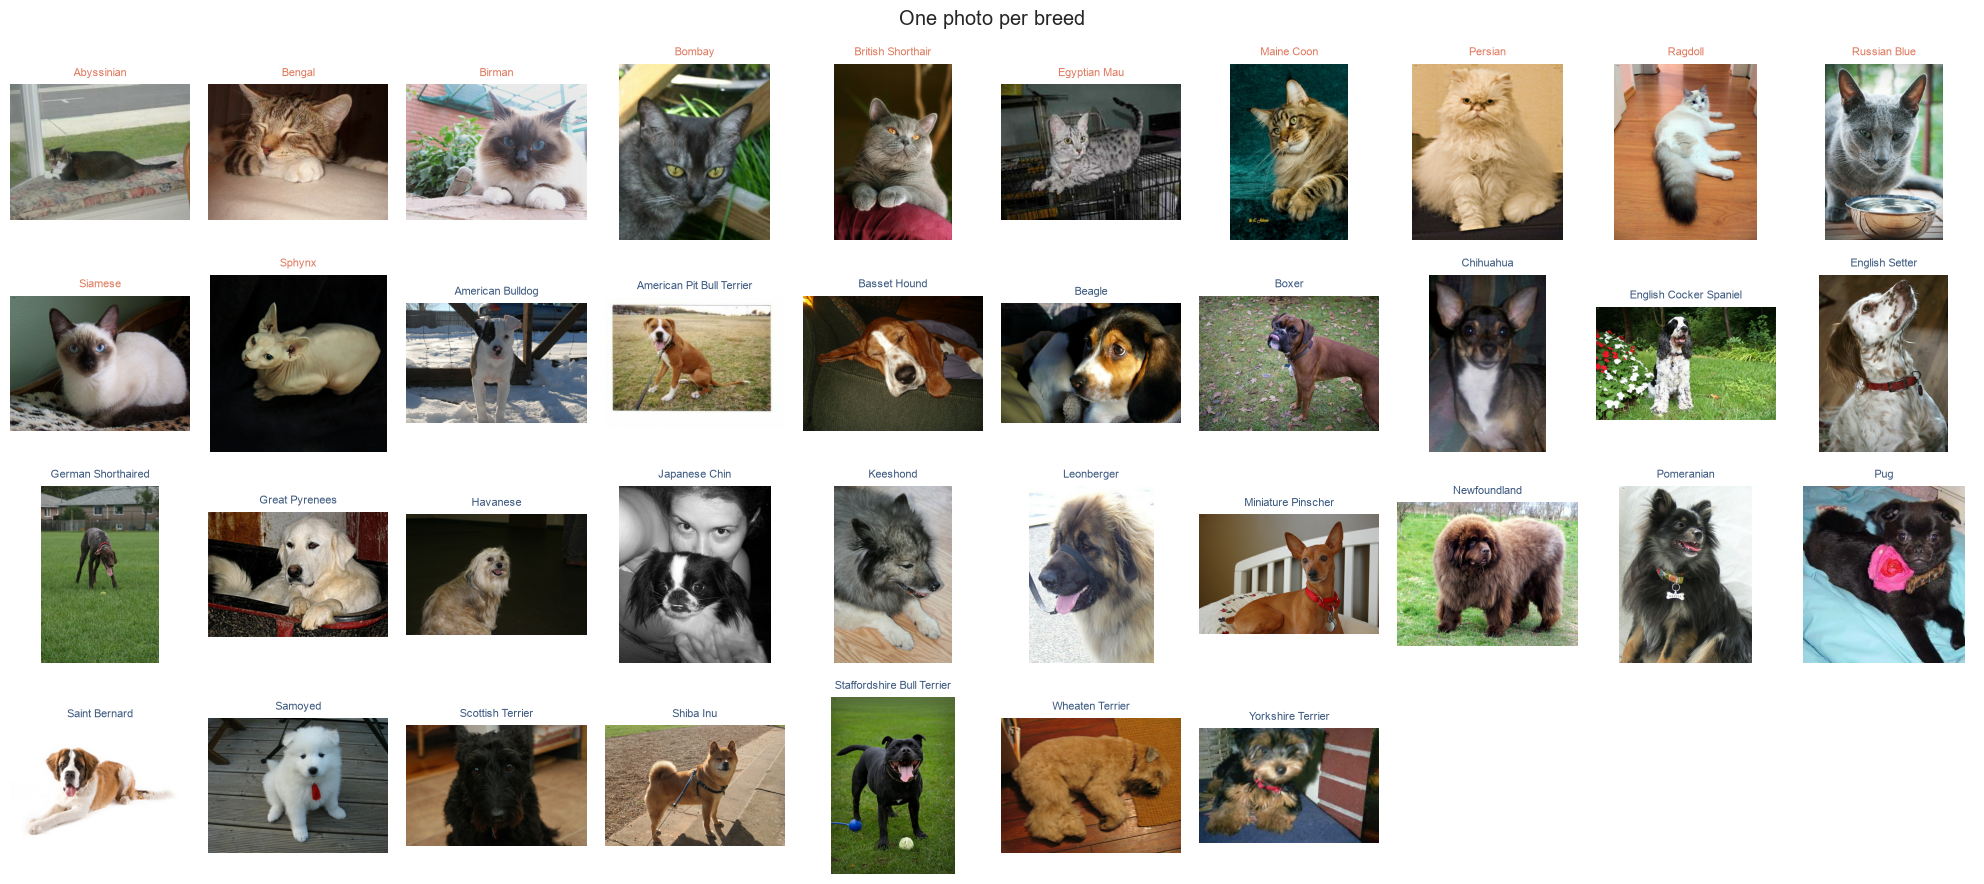

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.2, 1]})
cnt = meta_all.groupby(["breed", "species"]).size().reset_index(name="n").sort_values(["species", "n"])
axes[0].barh(cnt["breed"], cnt["n"], color=[SPECIES_COLORS[s] for s in cnt["species"]])
axes[0].set_title("Photos per breed (orange = cat, blue = dog)"); axes[0].tick_params(axis="y", labelsize=7)
sns.scatterplot(data=meta_all.sample(min(3000, len(meta_all)), random_state=SEED), x="width", y="height",
                hue="species", palette=SPECIES_COLORS, s=10, alpha=0.5, ax=axes[1])
axes[1].set_title("Image sizes")
plt.tight_layout(); save_fig("eda_counts"); plt.show()
RESULTS["data"]["per_breed"] = meta_all.groupby("breed").size().to_dict()
RESULTS["data"]["size_median"] = [int(meta_all["width"].median()), int(meta_all["height"].median())]

# one example per breed
firsts = meta_train.drop_duplicates("label").set_index("label")["file"].to_dict()
want = set(firsts.values()); found = {}
for ex in train_raw.as_numpy_iterator():
    f = ex["file_name"].decode()
    if f in want:
        found[f] = ex["image"]
    if len(found) == len(want):
        break
fig, axes = plt.subplots(4, 10, figsize=(20, 9))
for ax in axes.ravel(): ax.axis("off")
for k, lab in enumerate(sorted(firsts, key=lambda l: (BREED_SPECIES[l], BREEDS[l]))):
    ax = axes.ravel()[k]; ax.imshow(found[firsts[lab]])
    ax.set_title(BREEDS[lab], fontsize=8, color=SPECIES_COLORS[BREED_SPECIES[lab]])
plt.suptitle("One photo per breed"); plt.tight_layout(); save_fig("breed_gallery"); plt.show()

**Takeaway:** balanced (~200 per breed), 2:1 dogs to cats in breeds, sizes vary → resize to 224×224.

## 3. Model selection
Ten candidates, all judged on the **same validation set**:

| Family | Models | How |
|---|---|---|
| Baselines | majority class; colour histogram + logistic regression | hand-made features |
| From scratch | 4-block CNN with augmentation | trained end-to-end |
| Transfer learning | MobileNetV2, MobileNetV3-Large, EfficientNetB0, ResNet50V2, DenseNet121, ConvNeXt-Tiny (GPU only) | frozen ImageNet backbone → cached features → trained softmax head |
| Ensemble | best two backbones, features concatenated | same head |

Recorded for each: validation accuracy, top-5 accuracy, size (parameters) and speed (ms per image).

In [5]:
FILE_SPLIT = dict(zip(meta_all["file"], meta_all["split"].map({"train": 0, "val": 1, "test": 2})))
LABEL_OF = dict(zip(meta_all["file"], meta_all["label"]))
table = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(
    tf.constant(list(FILE_SPLIT)), tf.constant(list(FILE_SPLIT.values()), dtype=tf.int64)), default_value=-1)

def images(split, size=IMG, batch=32):
    k = {"train": 0, "val": 1, "test": 2}[split]
    src = test_raw if split == "test" else train_raw
    ds = src.filter(lambda e: table.lookup(e["file_name"]) == k)
    ds = ds.map(lambda e: (tf.cast(tf.image.resize(e["image"], (size, size)), tf.float32), e["label"], e["file_name"]),
                num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

# labels / file order per split (identical for every pass because nothing is shuffled)
Y, FILES = {}, {}
for s in ("train", "val", "test"):
    ys, fs = [], []
    for _, yb, fb in images(s, size=32):
        ys.append(yb.numpy()); fs += [f.decode() for f in fb.numpy()]
    Y[s], FILES[s] = np.concatenate(ys), fs
print({s: len(Y[s]) for s in Y})

{'train': 3128, 'val': 552, 'test': 3669}


In [6]:
# --- baselines -------------------------------------------------------------
def colour_hist(split):
    feats = []
    for xb, _, _ in images(split, size=128):
        h = [tf.map_fn(lambda im: tf.cast(tf.histogram_fixed_width(im[..., c], [0., 256.], nbins=16), tf.float32), xb) for c in range(3)]
        feats.append((tf.concat(h, axis=1) / (128 * 128)).numpy())
    return np.concatenate(feats)

H = {s: colour_hist(s) for s in ("train", "val")}
selection = []
maj = np.bincount(Y["train"]).argmax()
selection.append(dict(model="Majority class", family="baseline", val_acc=float((Y["val"] == maj).mean()), val_top5=None,
                      params_m=0, ms_per_img=0.0))
t0 = time.perf_counter()
lr_hist = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(H["train"], Y["train"])
p = lr_hist.predict_proba(H["val"])
selection.append(dict(model="Colour histogram + LR", family="baseline", val_acc=accuracy_score(Y["val"], p.argmax(1)),
                      val_top5=top_k_accuracy_score(Y["val"], p, k=5, labels=range(len(BREEDS))), params_m=0, ms_per_img=0.0))
print(pd.DataFrame(selection).round(4))

                   model    family  val_acc  val_top5  params_m  ms_per_img
0         Majority class  baseline   0.0272       NaN         0         0.0
1  Colour histogram + LR  baseline   0.0743    0.2736         0         0.0


In [7]:
# --- CNN from scratch (end-to-end, 160 px, augmentation) -------------------
def scratch_cnn():
    inp = keras.Input((160, 160, 3))
    x = keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.08), layers.RandomZoom(0.1)])(inp)
    x = layers.Rescaling(1 / 255)(x)
    for f in (32, 64, 128, 256):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x); x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x); x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.4)(x)
    return keras.Model(inp, layers.Dense(len(BREEDS), activation="softmax")(x), name="scratch_cnn")

scratch_path = os.path.join(CACHE, "scratch.json")
if REUSE_SAVED and os.path.exists(scratch_path):
    sc = json.load(open(scratch_path)); print("loaded saved scratch-CNN result")
else:
    keras.utils.set_random_seed(SEED)
    m = scratch_cnn()
    m.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy",
              metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(5, name="top5")])
    tr = images("train", 160).unbatch().shuffle(2000, seed=SEED).map(lambda x, y, f: (x, y)).batch(32).prefetch(2)
    va = images("val", 160).map(lambda x, y, f: (x, y))
    t0 = time.perf_counter()
    h = m.fit(tr, validation_data=va, epochs=BUDGET["scratch_epochs"], verbose=2,
              callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=6, restore_best_weights=True)])
    b = int(np.argmin(h.history["val_loss"]))
    sc = dict(val_acc=float(h.history["val_accuracy"][b]), val_top5=float(h.history["val_top5"][b]),
              params_m=m.count_params() / 1e6, seconds=time.perf_counter() - t0,
              history={k: [float(v) for v in vals] for k, vals in h.history.items()})
    json.dump(sc, open(scratch_path, "w"))
    del m; keras.backend.clear_session(); gc.collect()
selection.append(dict(model="CNN from scratch", family="scratch", val_acc=sc["val_acc"], val_top5=sc["val_top5"],
                      params_m=sc["params_m"], ms_per_img=None))
print(f"CNN from scratch: val accuracy {sc['val_acc']:.3f}")

loaded saved scratch-CNN result
CNN from scratch: val accuracy 0.096


In [8]:
# --- pretrained backbones: extract features once, cache them ---------------
A = keras.applications
BACKBONES = {   # name: (constructor, preprocessing; None = built into the model, expects 0-255)
    "MobileNetV2":      (A.MobileNetV2,      A.mobilenet_v2.preprocess_input),
    "MobileNetV3Large": (A.MobileNetV3Large, None),
    "EfficientNetB0":   (A.EfficientNetB0,   None),
    "ResNet50V2":       (A.ResNet50V2,       A.resnet_v2.preprocess_input),
    "DenseNet121":      (A.DenseNet121,      A.densenet.preprocess_input),
    "ConvNeXtTiny":     (A.ConvNeXtTiny,     None),
}
if not ON_GPU:                       # ConvNeXt takes over an hour on a laptop CPU; it runs on a GPU (e.g. Colab)
    BACKBONES.pop("ConvNeXtTiny"); print("CPU run: ConvNeXtTiny skipped (GPU only)")
FEATS, BB_INFO = {}, {}
for name, (ctor, prep) in BACKBONES.items():
    path = os.path.join(CACHE, f"feat_{name}.npz")
    if REUSE_SAVED and os.path.exists(path):
        z = np.load(path); FEATS[name] = {s: z[s] for s in ("train", "val", "test")}
        BB_INFO[name] = json.loads(str(z["info"])); print(f"{name}: loaded cached features"); continue
    net = ctor(include_top=False, weights="imagenet", pooling="avg", input_shape=(IMG, IMG, 3))
    feats, n_img, secs = {}, 0, 0.0
    for s in ("train", "val", "test"):
        out = []
        for xb, _, _ in images(s, batch=32 if ON_GPU else 8):      # small batches on CPU keep memory low
            t0 = time.perf_counter()
            out.append(net(prep(xb) if prep else xb, training=False).numpy())
            secs += time.perf_counter() - t0; n_img += len(xb)
        feats[s] = np.concatenate(out).astype(np.float32)
    BB_INFO[name] = dict(params_m=net.count_params() / 1e6, dim=int(feats["train"].shape[1]), ms_per_img=1000 * secs / n_img)
    np.savez_compressed(path, info=json.dumps(BB_INFO[name]), **feats)
    FEATS[name] = feats
    print(f"{name}: {BB_INFO[name]['dim']}-d features, {BB_INFO[name]['ms_per_img']:.1f} ms/img")
    del net; keras.backend.clear_session(); gc.collect()

CPU run: ConvNeXtTiny skipped (GPU only)


MobileNetV2: loaded cached features


MobileNetV3Large: loaded cached features


EfficientNetB0: loaded cached features


ResNet50V2: loaded cached features
DenseNet121: loaded cached features


In [9]:
def train_head(Xtr, ytr, Xva, yva, lr=1e-3, dropout=0.3, l2=0.0, batch=64, epochs=None):
    keras.utils.set_random_seed(SEED)
    reg = keras.regularizers.l2(l2) if l2 else None
    m = keras.Sequential([keras.Input((Xtr.shape[1],)), layers.Dropout(dropout),
                          layers.Dense(len(BREEDS), activation="softmax", kernel_regularizer=reg)])
    m.compile(keras.optimizers.Adam(lr), "sparse_categorical_crossentropy",
              metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(5, name="top5")])
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs or BUDGET["head_epochs"], batch_size=batch, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=8, restore_best_weights=True)])
    return m, {k: [float(v) for v in vals] for k, vals in h.history.items()}

HEAD_HIST = {}
for name in BACKBONES:
    F = FEATS[name]
    m, hist = train_head(F["train"], Y["train"], F["val"], Y["val"])
    b = int(np.argmin(hist["val_loss"])); HEAD_HIST[name] = hist
    selection.append(dict(model=name, family="transfer", val_acc=hist["val_accuracy"][b], val_top5=hist["val_top5"][b],
                          val_loss=hist["val_loss"][b], params_m=BB_INFO[name]["params_m"], ms_per_img=BB_INFO[name]["ms_per_img"]))
    del m; keras.backend.clear_session()

top2 = sorted([r for r in selection if r["family"] == "transfer"], key=lambda r: -r["val_acc"])[:2]
ens = [r["model"] for r in top2]
cat = {s: np.hstack([FEATS[n][s] for n in ens]) for s in ("train", "val", "test")}
m, hist = train_head(cat["train"], Y["train"], cat["val"], Y["val"]); b = int(np.argmin(hist["val_loss"]))
HEAD_HIST["Ensemble"] = hist
selection.append(dict(model=f"Ensemble: {ens[0]} + {ens[1]}", family="ensemble", val_acc=hist["val_accuracy"][b], val_top5=hist["val_top5"][b],
                      val_loss=hist["val_loss"][b], params_m=sum(BB_INFO[n]["params_m"] for n in ens),
                      ms_per_img=sum(BB_INFO[n]["ms_per_img"] for n in ens)))
del m; keras.backend.clear_session()

sel = pd.DataFrame(selection).set_index("model").sort_values("val_acc", ascending=False)
RESULTS["selection"] = {"table": sel.reset_index().round(5).to_dict(orient="records"), "ensemble_of": ens,
                        "scratch_history": sc.get("history"), "head_histories": HEAD_HIST}
sel.round(4)

,family,val_acc,val_top5,params_m,ms_per_img,val_loss
model,,,,,,
Ensemble: EfficientNetB0 + DenseNet121,ensemble,0.9493,0.9964,11.0871,176.6930,0.1403
EfficientNetB0,transfer,0.9402,0.9964,4.0496,62.3571,0.1617
DenseNet121,transfer,0.9366,0.9982,7.0375,114.3360,0.2175
MobileNetV2,transfer,0.9257,0.9946,2.2580,37.6785,0.2208
MobileNetV3Large,transfer,0.9203,0.9946,2.9964,37.1269,0.2546
ResNet50V2,transfer,0.8967,0.9928,23.5648,92.9100,0.3045
CNN from scratch,scratch,0.0960,0.3043,0.3994,NaN,NaN
Colour histogram + LR,baseline,0.0743,0.2736,0.0000,0.0000,NaN
Majority class,baseline,0.0272,NaN,0.0000,0.0000,NaN


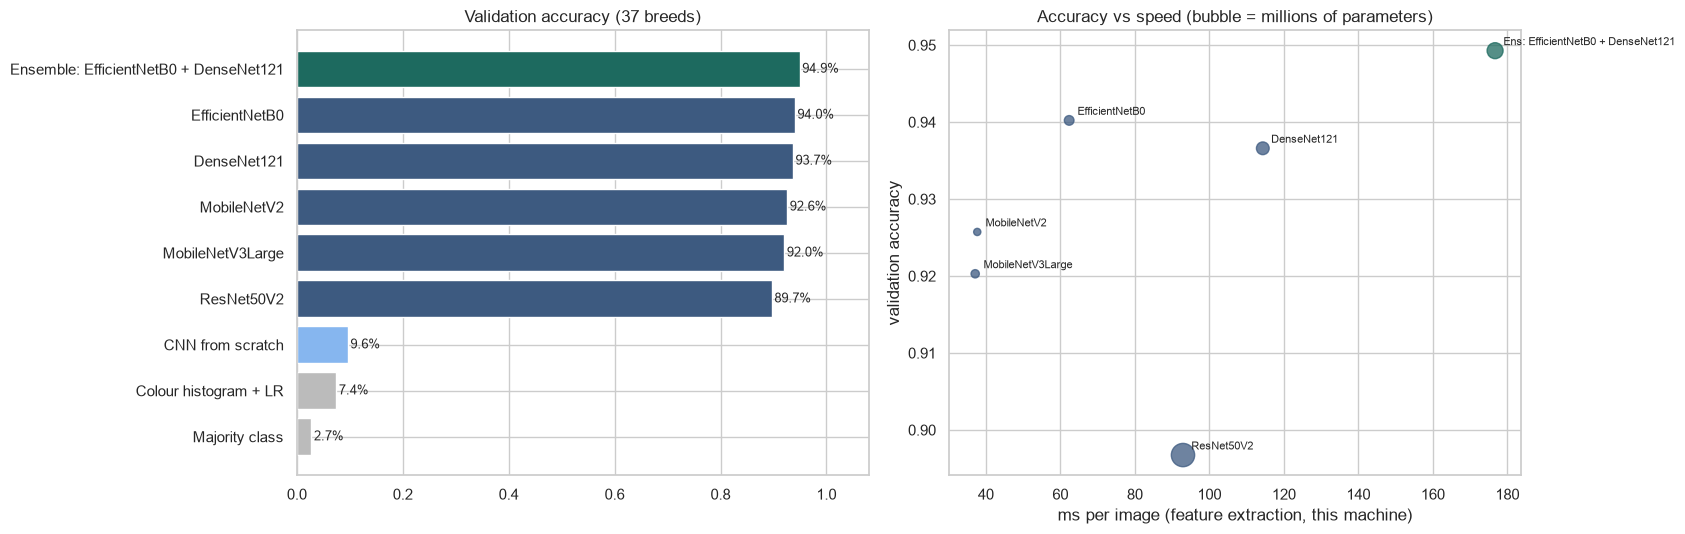

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
fam_col = {"baseline": "#BBBBBB", "scratch": "#86b6ef", "transfer": "#3D5A80", "ensemble": "#1d6a5f"}
s2 = sel.sort_values("val_acc")
axes[0].barh(s2.index, s2["val_acc"], color=[fam_col[f] for f in s2["family"]])
for i, v in enumerate(s2["val_acc"]): axes[0].text(v + 0.005, i, f"{v:.1%}", va="center", fontsize=9)
axes[0].set_xlim(0, 1.08); axes[0].set_title("Validation accuracy (37 breeds)")
tl = sel[sel["family"].isin(["transfer", "ensemble"])]
axes[1].scatter(tl["ms_per_img"], tl["val_acc"], s=tl["params_m"] * 12, c=[fam_col[f] for f in tl["family"]], alpha=0.75)
for n, r in tl.iterrows(): axes[1].annotate(n.replace("Ensemble: ", "Ens: "), (r["ms_per_img"], r["val_acc"]), fontsize=8, xytext=(6, 4), textcoords="offset points")
axes[1].set_xlabel("ms per image (feature extraction, this machine)"); axes[1].set_ylabel("validation accuracy")
axes[1].set_title("Accuracy vs speed (bubble = millions of parameters)")
plt.tight_layout(); save_fig("selection"); plt.show()

In [11]:
BEST = sel[sel["family"] == "transfer"].index[0]          # best single backbone
WINNER = sel.index[0]
use_ens = WINNER.startswith("Ensemble") and sel.loc[WINNER, "val_acc"] - sel.loc[BEST, "val_acc"] > 0.005
FINAL_NAME = WINNER if use_ens else BEST
FINAL_F = cat if use_ens else FEATS[BEST]
print(f"best single backbone: {BEST} | overall best: {WINNER} | final choice: {FINAL_NAME}")
RESULTS["selection"].update(best_single=BEST, winner=WINNER, final=FINAL_NAME, use_ensemble=bool(use_ens))

best single backbone: EfficientNetB0 | overall best: Ensemble: EfficientNetB0 + DenseNet121 | final choice: Ensemble: EfficientNetB0 + DenseNet121


**Rule:** take the ensemble only if it beats the best single backbone by more than 0.5 percentage points
(it costs two backbones at prediction time); otherwise take the best single backbone.

### Observations — model selection
* **Pretrained beats from-scratch by a mile:** the CNN trained from scratch reaches 9.6 % on 37 breeds
  (≈ 85 photos per breed are far too few to learn features from zero); every pretrained network is above 90 %.
* **Ranking:** EfficientNetB0 94.0 %, DenseNet121 93.7 %, MobileNetV2 92.6 %, MobileNetV3Large 92.0 %, ResNet50V2 89.7 %.
* **Bigger is not better:** ResNet50V2 has the most parameters (23.6 M) but ranks 5 of 5;
  EfficientNetB0 wins with 4.0 M.
* **Speed:** MobileNetV3Large is the fastest (37 ms/image on this CPU) and only 2.0 points behind the best — the choice for a phone app.
* **Ensemble:** EfficientNetB0 + DenseNet121 reaches 94.9 % — 0.9 points above the best single network, so it is the final model (at the cost of running two networks).
* *Note:* ConvNeXt-Tiny runs only on a GPU (over an hour on a laptop CPU), so this CPU run compares five pretrained networks.

## 4. Tuning (grid search on the chosen features)

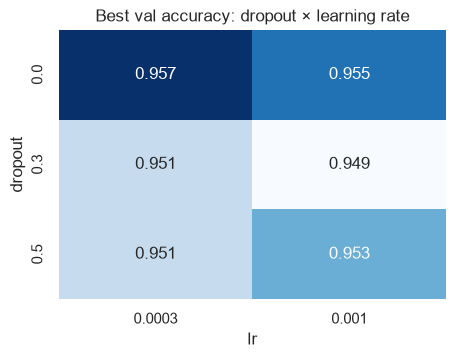

best: {'lr': 0.0003, 'dropout': 0.0, 'l2': 0.0001}


,lr,dropout,l2,epochs,val_acc,val_loss
0,0.0003,0.0,0.0001,82,0.9565,0.1719
1,0.0003,0.0,0.0000,91,0.9547,0.1530
2,0.0010,0.0,0.0001,41,0.9547,0.1725
3,0.0010,0.0,0.0000,39,0.9529,0.1527
4,0.0010,0.5,0.0001,40,0.9529,0.1566
5,0.0010,0.5,0.0000,40,0.9511,0.1356


In [12]:
grid = dict(lr=[1e-3, 3e-4], dropout=[0.0, 0.3, 0.5], l2=[0.0, 1e-4], batch=[64])
trials = []
for lr, dr, l2, bs in itertools.product(*grid.values()):
    m, hist = train_head(FINAL_F["train"], Y["train"], FINAL_F["val"], Y["val"], lr=lr, dropout=dr, l2=l2, batch=bs)
    b = int(np.argmin(hist["val_loss"]))
    trials.append(dict(lr=lr, dropout=dr, l2=l2, epochs=len(hist["loss"]), val_acc=hist["val_accuracy"][b], val_loss=hist["val_loss"][b]))
    del m; keras.backend.clear_session()
tune = pd.DataFrame(trials).sort_values(["val_acc", "val_loss"], ascending=[False, True]).reset_index(drop=True)
BEST_HP = {k: (float(tune.iloc[0][k]) if k != "epochs" else int(tune.iloc[0][k])) for k in ("lr", "dropout", "l2")}
RESULTS["tuning"] = {"trials": tune.round(5).to_dict(orient="records"), "best": BEST_HP}

piv = tune.pivot_table(index="dropout", columns="lr", values="val_acc", aggfunc="max")
fig, ax = plt.subplots(figsize=(5, 3.5)); sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Best val accuracy: dropout × learning rate"); save_fig("tuning"); plt.show()
print("best:", BEST_HP); tune.head(6).round(4)

## 5. Evaluation on the test set

In [13]:
final, fhist = train_head(FINAL_F["train"], Y["train"], FINAL_F["val"], Y["val"], **BEST_HP)
P = final.predict(FINAL_F["test"], verbose=0); yp = P.argmax(1); yt = Y["test"]
sp = np.array(BREED_SPECIES)
metrics = dict(top1=accuracy_score(yt, yp), top5=top_k_accuracy_score(yt, P, k=5, labels=range(len(BREEDS))),
               macro_f1=f1_score(yt, yp, average="macro"), species_acc=float((sp[yt] == sp[yp]).mean()),
               cat_breeds_acc=accuracy_score(yt[sp[yt] == "Cat"], yp[sp[yt] == "Cat"]),
               dog_breeds_acc=accuracy_score(yt[sp[yt] == "Dog"], yp[sp[yt] == "Dog"]), n_test=int(len(yt)))
rng = np.random.default_rng(SEED)
boot = [accuracy_score(yt[i], yp[i]) for i in (rng.integers(0, len(yt), len(yt)) for _ in range(1000))]
metrics["top1_ci95"] = [float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))]
RESULTS["test"] = metrics
pd.Series(metrics)

top1                                              0.931589
top5                                              0.996729
macro_f1                                          0.930816
species_acc                                       0.997547
cat_breeds_acc                                    0.890955
dog_breeds_acc                                    0.950925
n_test                                                3669
top1_ci95         [0.9234123739438539, 0.9400381575361134]
dtype: object

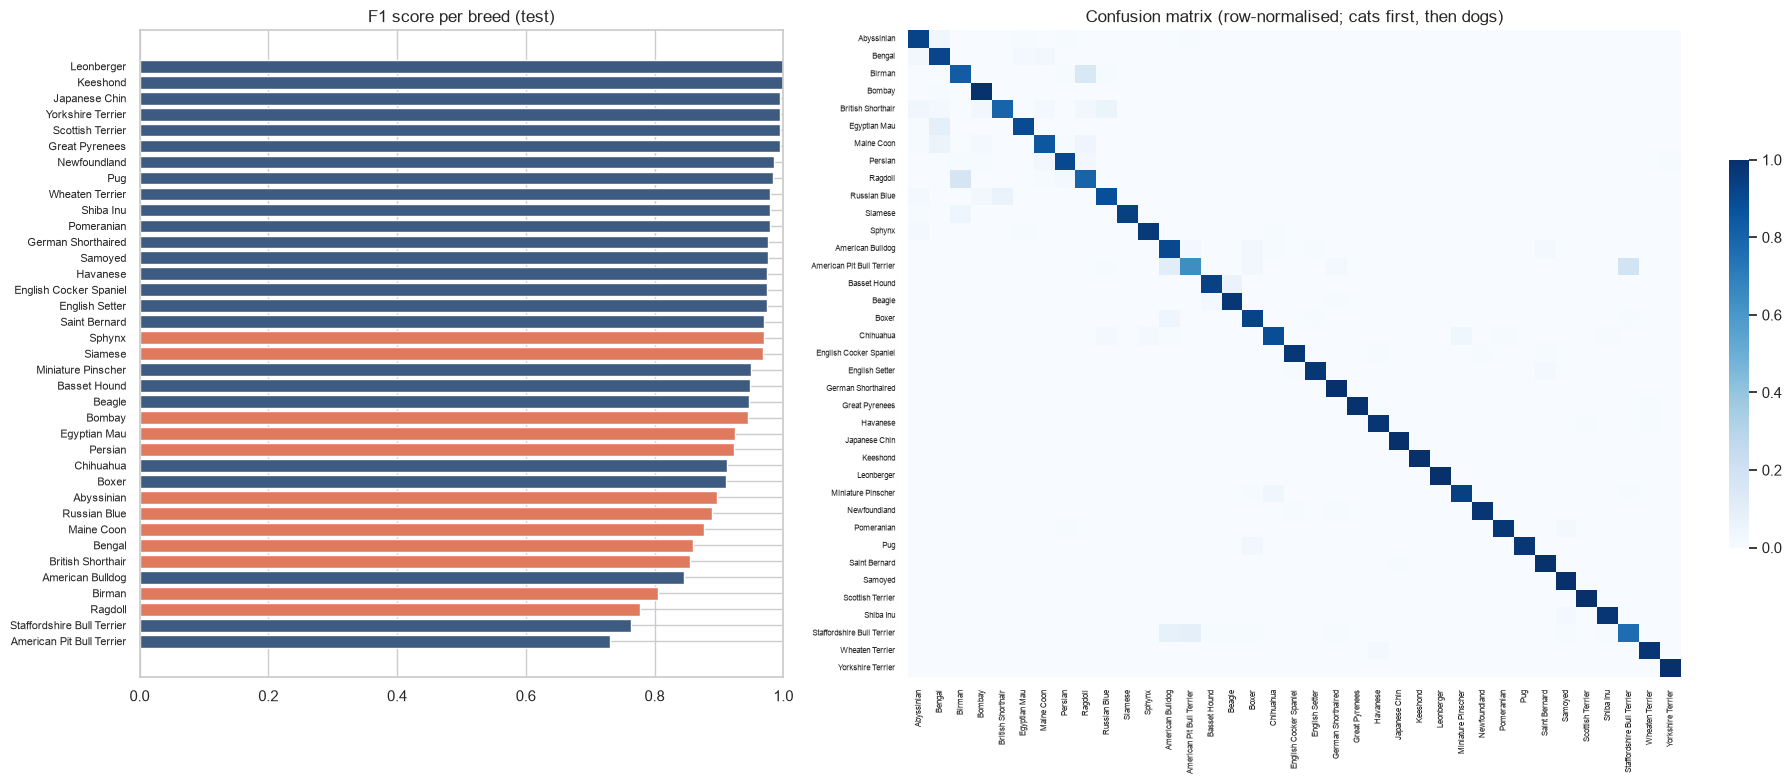

,true breed,predicted as,photos
0,American Pit Bull Terrier,Staffordshire Bull Terrier,19
1,Ragdoll,Birman,17
2,Birman,Ragdoll,15
3,American Pit Bull Terrier,American Bulldog,11
4,Egyptian Mau,Bengal,9
5,Staffordshire Bull Terrier,American Pit Bull Terrier,8
6,Basset Hound,Beagle,7
7,Russian Blue,British Shorthair,7
8,Staffordshire Bull Terrier,American Bulldog,7
9,British Shorthair,Russian Blue,6


In [14]:
f1s = f1_score(yt, yp, average=None, labels=range(len(BREEDS)))
per = pd.DataFrame({"breed": BREEDS, "species": BREED_SPECIES, "f1": f1s}).sort_values("f1")
cm = confusion_matrix(yt, yp, labels=range(len(BREEDS)))
pairs = [(BREEDS[i], BREEDS[j], int(cm[i, j])) for i in range(len(BREEDS)) for j in range(len(BREEDS)) if i != j and cm[i, j] > 0]
pairs = sorted(pairs, key=lambda t: -t[2])[:10]
RESULTS["per_breed"] = per.round(4).to_dict(orient="records")
RESULTS["confused_pairs"] = [dict(true=a, pred=b, n=n) for a, b, n in pairs]

fig, axes = plt.subplots(1, 2, figsize=(19, 8), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].barh(per["breed"], per["f1"], color=[SPECIES_COLORS[s] for s in per["species"]])
axes[0].set_xlim(0, 1); axes[0].set_title("F1 score per breed (test)"); axes[0].tick_params(axis="y", labelsize=8)
order = sorted(range(len(BREEDS)), key=lambda i: (BREED_SPECIES[i], BREEDS[i]))
cmn = cm[np.ix_(order, order)] / np.maximum(cm[np.ix_(order, order)].sum(1, keepdims=True), 1)
sns.heatmap(cmn, cmap="Blues", vmin=0, vmax=1, ax=axes[1], cbar_kws={"shrink": 0.6},
            xticklabels=[BREEDS[i] for i in order], yticklabels=[BREEDS[i] for i in order])
axes[1].tick_params(labelsize=6); axes[1].set_title("Confusion matrix (row-normalised; cats first, then dogs)")
plt.tight_layout(); save_fig("per_breed_confusion"); plt.show()
pd.DataFrame(pairs, columns=["true breed", "predicted as", "photos"])

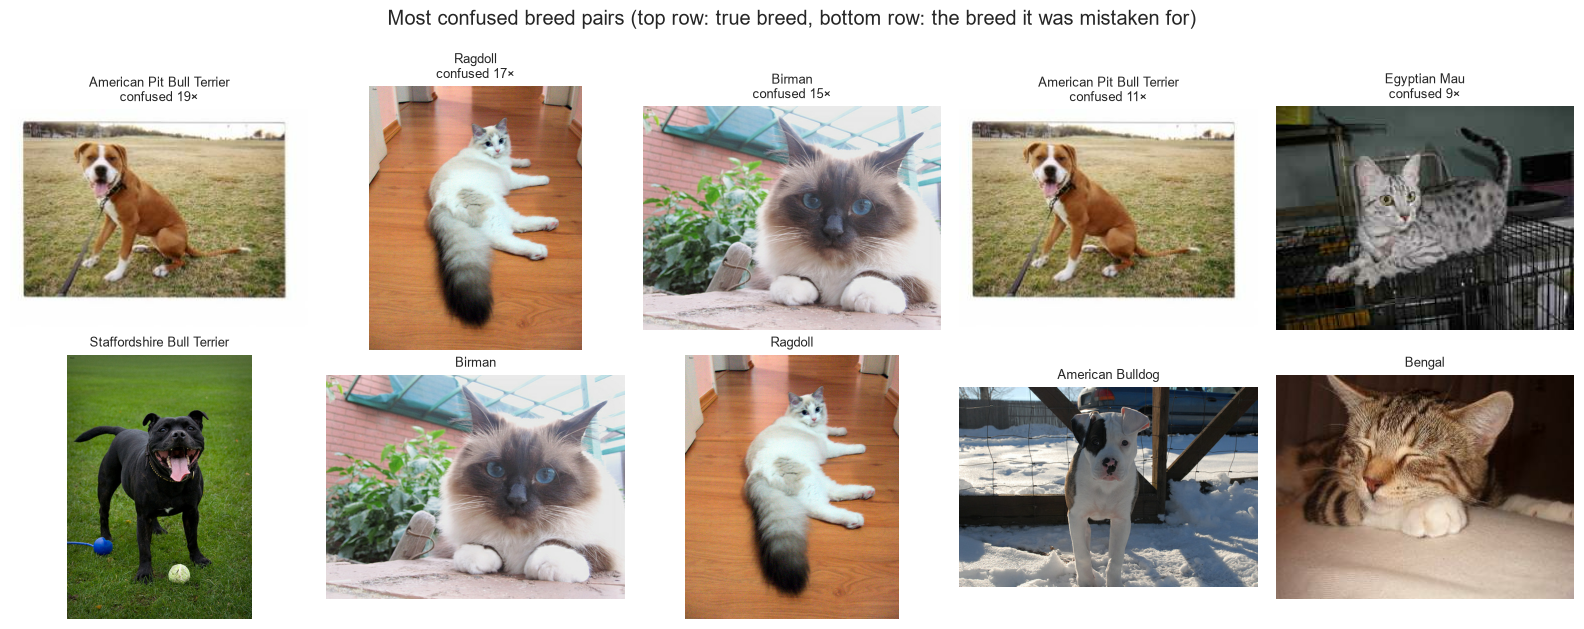

In [15]:
# examples for the most confused pairs: one photo of each breed side by side
need = {}
for a, b_, _ in pairs[:5]:
    for br in (a, b_):
        lab = BREEDS.index(br)
        need[br] = meta_train[meta_train["label"] == lab]["file"].iloc[0]
got = {}
for ex in train_raw.as_numpy_iterator():
    f = ex["file_name"].decode()
    if f in need.values(): got[f] = ex["image"]
    if len(got) == len(set(need.values())): break
fig, axes = plt.subplots(2, min(5, len(pairs)), figsize=(3.2 * min(5, len(pairs)), 6.4), squeeze=False)
for k, (a, b_, n) in enumerate(pairs[:5]):
    for r, br in enumerate((a, b_)):
        ax = axes[r, k]; ax.imshow(got[need[br]]); ax.axis("off")
        ax.set_title(f"{br}" + (f"\nconfused {n}×" if r == 0 else ""), fontsize=9)
plt.suptitle("Most confused breed pairs (top row: true breed, bottom row: the breed it was mistaken for)")
plt.tight_layout(); save_fig("confused_pairs"); plt.show()

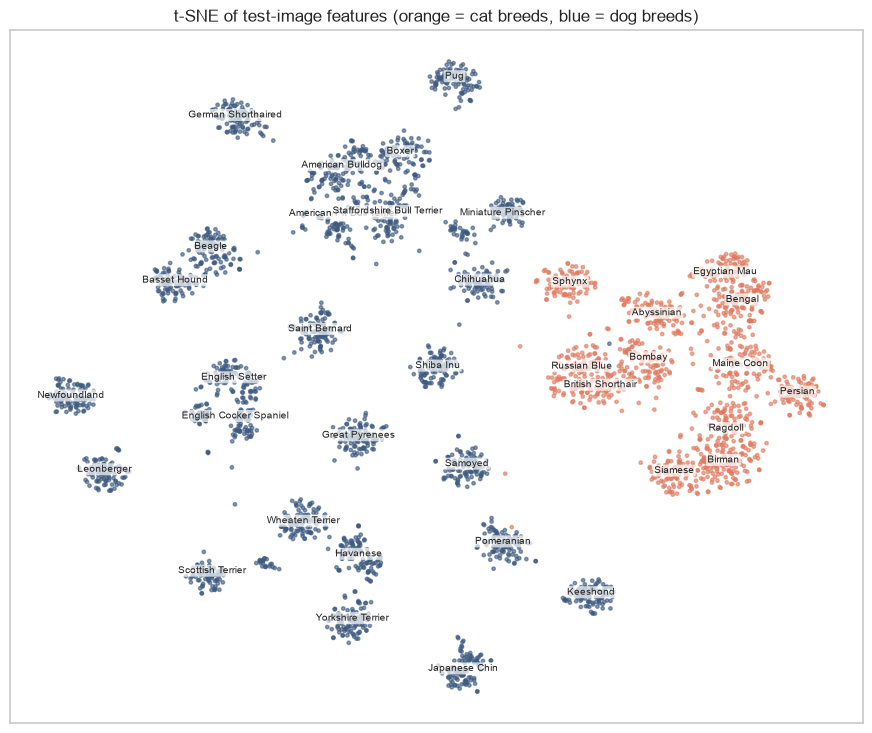

In [16]:
# embedding map: t-SNE of the final model's test features
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(FINAL_F["test"])
fig, ax = plt.subplots(figsize=(11, 9))
ax.scatter(emb[:, 0], emb[:, 1], c=[SPECIES_COLORS[BREED_SPECIES[l]] for l in yt], s=6, alpha=0.6)
for lab in range(len(BREEDS)):
    pts = emb[yt == lab]
    if len(pts): ax.text(*np.median(pts, axis=0), BREEDS[lab], fontsize=7, ha="center",
                         bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))
ax.set_title("t-SNE of test-image features (orange = cat breeds, blue = dog breeds)"); ax.set_xticks([]); ax.set_yticks([])
save_fig("tsne"); plt.show()
RESULTS["tsne"] = {"x": np.round(emb[:, 0], 2).tolist(), "y": np.round(emb[:, 1], 2).tolist(),
                   "label": yt.astype(int).tolist(), "correct": (yp == yt).astype(int).tolist()}

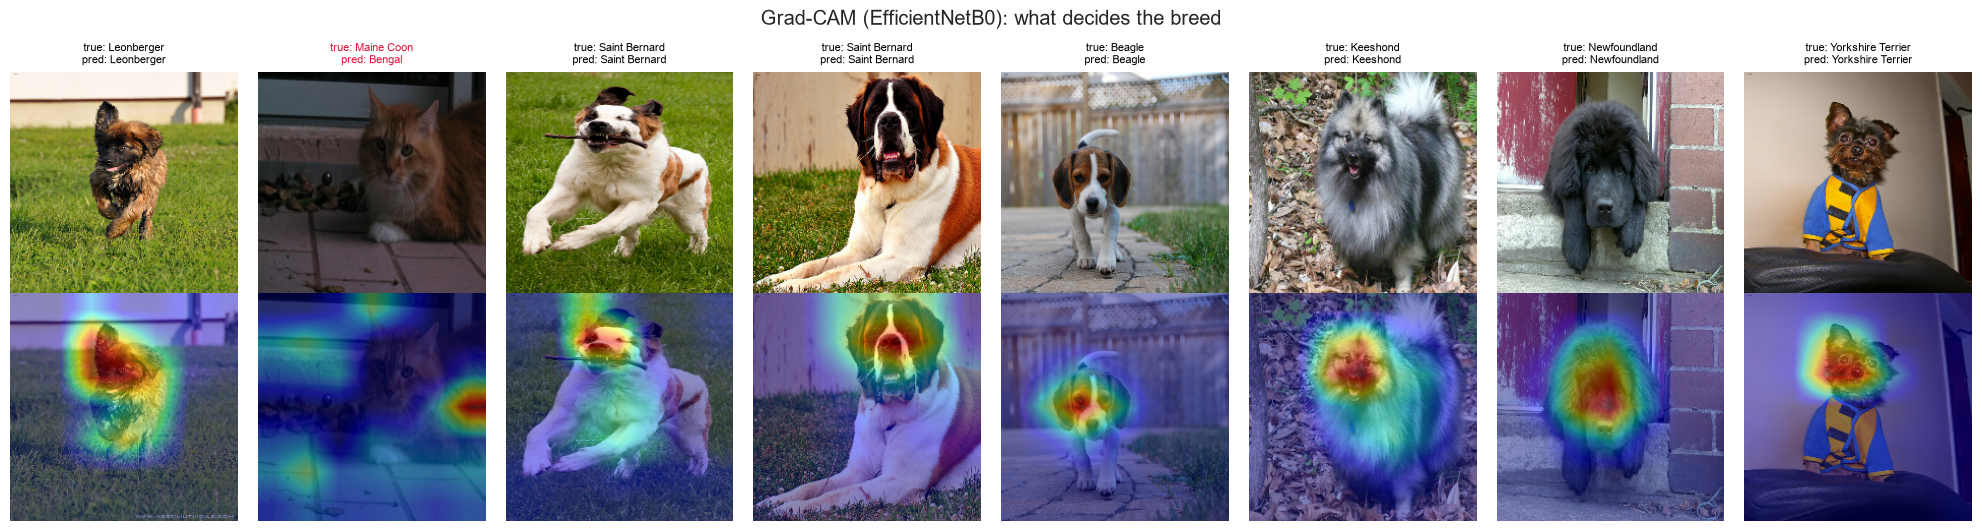

In [17]:
# Grad-CAM with the best single backbone + its own head (needs the spatial feature maps)
ctor, prep = BACKBONES[BEST]
net = ctor(include_top=False, weights="imagenet", pooling=None, input_shape=(IMG, IMG, 3))
gc_head, _ = train_head(FEATS[BEST]["train"], Y["train"], FEATS[BEST]["val"], Y["val"], **BEST_HP)
ex_imgs, ex_y = [], []
for xb, yb, _ in images("test", batch=64).take(1):
    ex_imgs, ex_y = xb.numpy()[:8], yb.numpy()[:8]
fig, axes = plt.subplots(2, 8, figsize=(20, 5.4))
for k, (img, y) in enumerate(zip(ex_imgs, ex_y)):
    x = tf.constant(img[None])
    x = prep(x) if prep else x
    with tf.GradientTape() as tape:
        fmap = net(x, training=False); tape.watch(fmap)
        probs = gc_head(tf.reduce_mean(fmap, axis=(1, 2)), training=False)
        cls = int(tf.argmax(probs[0])); score = probs[:, cls]
    g = tape.gradient(score, fmap)
    cam = tf.nn.relu(tf.reduce_sum(fmap * tf.reduce_mean(g, axis=(1, 2))[:, None, None, :], axis=-1))[0]
    cam = tf.image.resize((cam / (tf.reduce_max(cam) + 1e-8))[..., None], (IMG, IMG)).numpy()[..., 0]
    axes[0, k].imshow(img.astype("uint8")); axes[1, k].imshow(img.astype("uint8")); axes[1, k].imshow(cam, cmap="jet", alpha=0.45)
    axes[0, k].set_title(f"true: {BREEDS[y]}\npred: {BREEDS[cls]}", fontsize=8, color="black" if cls == y else "crimson")
for ax in axes.ravel(): ax.axis("off")
plt.suptitle(f"Grad-CAM ({BEST}): what decides the breed"); plt.tight_layout(); save_fig("gradcam"); plt.show()
del net; keras.backend.clear_session()

### Observations — evaluation
* **Test:** top-1 **93.16 %** (95 % CI 92.34 % – 94.00 %), top-5 99.67 %, macro-F1 0.931 on 3,669 photos.
* **Cat vs dog for free:** reading the species off the predicted breed is right 99.75 % of the time.
* **Cats are harder:** cat breeds 89.1 % vs dog breeds 95.1 %.
* **Hardest breeds:** American Pit Bull Terrier (0.73), Staffordshire Bull Terrier (0.76), Ragdoll (0.78), Birman (0.81), American Bulldog (0.85). **Easiest:** Scottish Terrier (0.99), Yorkshire Terrier (0.99), Japanese Chin (0.99), Keeshond (1.00), Leonberger (1.00).
* **Confusions are between look-alikes:** American Pit Bull Terrier → Staffordshire Bull Terrier (19×); Ragdoll → Birman (17×); Birman → Ragdoll (15×); American Pit Bull Terrier → American Bulldog (11×); Egyptian Mau → Bengal (9×) — breeds that people also mix up.
* **Embedding map:** breeds form separate islands and all cat breeds sit apart from the dogs; look-alike breeds (Ragdoll/Birman/Siamese, Russian Blue/British Shorthair, the bull-terrier group) overlap.
* **Grad-CAM:** correct predictions focus on the face and head; in the misclassified example the attention drifts to the background.

## 6. Summary

In [18]:
def json_safe(o):
    if isinstance(o, dict): return {str(k): json_safe(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [json_safe(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, (float, np.floating)): return None if np.isnan(o) else float(o)
    return o
json.dump(json_safe(RESULTS), open(os.path.join(RES, "metrics.json"), "w"), indent=1)
final.save(os.path.join(RES, "breed_head.keras"))
pd.DataFrame([
    ("Data", f"{len(Y['train']):,} train / {len(Y['val']):,} val / {len(Y['test']):,} test photos, 37 breeds"),
    ("Candidates", f"{len(sel)} models; best single backbone {BEST} ({sel.loc[BEST, 'val_acc']:.1%} val)"),
    ("Final model", f"{FINAL_NAME} features + softmax head {BEST_HP}"),
    ("Test", f"top-1 {metrics['top1']:.2%} (95% CI {metrics['top1_ci95'][0]:.2%}–{metrics['top1_ci95'][1]:.2%}), top-5 {metrics['top5']:.2%}, macro-F1 {metrics['macro_f1']:.3f}"),
    ("Cat vs dog from breed", f"{metrics['species_acc']:.2%}"),
], columns=["stage", "result"]).set_index("stage")

,result
stage,
Data,"3,128 train / 552 val / 3,669 test photos, 37 ..."
Candidates,9 models; best single backbone EfficientNetB0 ...
Final model,Ensemble: EfficientNetB0 + DenseNet121 feature...
Test,"top-1 93.16% (95% CI 92.34%–94.00%), top-5 99...."
Cat vs dog from breed,99.75%


### Conclusions
1. Fine-grained recognition needs pretrained features: from scratch 10 %, pretrained 90 %–94 %.
2. Model choice is a trade-off: EfficientNetB0 is the best single network; MobileNetV3Large is nearly as good and the fastest; the ensemble adds accuracy at double cost.
3. Final model: **Ensemble: EfficientNetB0 + DenseNet121** → **93.2 % test accuracy on 37 breeds**, 99.7 % top-5, and cat vs dog 99.75 %.
4. Remaining errors are look-alike breeds (bull terriers, Ragdoll/Birman); more photos of those breeds or fine-tuning the backbone are the next steps.


In [19]:
if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive("results_breeds", "zip", RES)
    files.download("results_breeds.zip")